In [14]:
from pathlib import Path
from zipfile import ZipFile

proyecto = Path.cwd()

if proyecto.name == "notebooks":
    proyecto = proyecto.parent

ruta_zip = proyecto / "data" / "raw" / "beijing+multi+site+air+quality+data.zip"

print("Archivo encontrado:", ruta_zip.is_file())

with ZipFile(ruta_zip) as zip_datos:
    archivos = zip_datos.namelist()

print("Cantidad de elementos:", len(archivos))

for archivo in archivos:
    print(archivo)

Archivo encontrado: True
Cantidad de elementos: 4
PRSA2017_Data_20130301-20170228.zip
2A2478DC-8517-4490-9FA7-36F9A7A542BE.JPG
data.csv
test.csv


In [15]:
from io import BytesIO

with ZipFile(ruta_zip) as archivo_externo:
    contenido = archivo_externo.read("PRSA2017_Data_20130301-20170228.zip")

with ZipFile(BytesIO(contenido)) as archivo_interno:
    archivos_csv = [
        nombre
        for nombre in archivo_interno.namelist()
        if nombre.lower().endswith(".csv")
    ]

print("Archivos CSV encontrados:", len(archivos_csv))

for nombre in archivos_csv:
    print(nombre)

Archivos CSV encontrados: 12
PRSA_Data_20130301-20170228/PRSA_Data_Aotizhongxin_20130301-20170228.csv
PRSA_Data_20130301-20170228/PRSA_Data_Changping_20130301-20170228.csv
PRSA_Data_20130301-20170228/PRSA_Data_Dingling_20130301-20170228.csv
PRSA_Data_20130301-20170228/PRSA_Data_Dongsi_20130301-20170228.csv
PRSA_Data_20130301-20170228/PRSA_Data_Guanyuan_20130301-20170228.csv
PRSA_Data_20130301-20170228/PRSA_Data_Gucheng_20130301-20170228.csv
PRSA_Data_20130301-20170228/PRSA_Data_Huairou_20130301-20170228.csv
PRSA_Data_20130301-20170228/PRSA_Data_Nongzhanguan_20130301-20170228.csv
PRSA_Data_20130301-20170228/PRSA_Data_Shunyi_20130301-20170228.csv
PRSA_Data_20130301-20170228/PRSA_Data_Tiantan_20130301-20170228.csv
PRSA_Data_20130301-20170228/PRSA_Data_Wanliu_20130301-20170228.csv
PRSA_Data_20130301-20170228/PRSA_Data_Wanshouxigong_20130301-20170228.csv


In [16]:
import pandas as pd

with ZipFile(BytesIO(contenido)) as archivo_interno:
    with archivo_interno.open(archivos_csv[0]) as archivo:
        df_estacion = pd.read_csv(archivo)

print("Estación:", archivos_csv[0])
print("Dimensiones:", df_estacion.shape)

df_estacion.head()

Estación: PRSA_Data_20130301-20170228/PRSA_Data_Aotizhongxin_20130301-20170228.csv
Dimensiones: (35064, 18)


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin


In [17]:
with ZipFile(BytesIO(contenido)) as archivo_interno:
    estaciones = {
        nombre: pd.read_csv(archivo_interno.open(nombre))
        for nombre in archivos_csv
    }

estructura = pd.DataFrame([
    {
        "archivo": nombre.split("/")[-1],
        "filas": len(datos),
        "columnas": len(datos.columns)
    }
    for nombre, datos in estaciones.items()
])

display(estructura)

columnas_iguales = all(
    list(datos.columns) == list(df_estacion.columns)
    for datos in estaciones.values()
)

print("Mismas columnas:", columnas_iguales)

,archivo,filas,columnas
0,PRSA_Data_Aotizhongxin_20130301-20170228.csv,35064,18
1,PRSA_Data_Changping_20130301-20170228.csv,35064,18
2,PRSA_Data_Dingling_20130301-20170228.csv,35064,18
3,PRSA_Data_Dongsi_20130301-20170228.csv,35064,18
4,PRSA_Data_Guanyuan_20130301-20170228.csv,35064,18
5,PRSA_Data_Gucheng_20130301-20170228.csv,35064,18
6,PRSA_Data_Huairou_20130301-20170228.csv,35064,18
7,PRSA_Data_Nongzhanguan_20130301-20170228.csv,35064,18
8,PRSA_Data_Shunyi_20130301-20170228.csv,35064,18
9,PRSA_Data_Tiantan_20130301-20170228.csv,35064,18


Mismas columnas: True


In [18]:
df = pd.concat(estaciones.values(), ignore_index=True)

print("Dimensiones:", df.shape)
print("Estaciones:", df["station"].nunique())

display(df.head())
display(df.dtypes)

Dimensiones: (420768, 18)
Estaciones: 12


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin


No           int64
year         int64
month        int64
day          int64
hour         int64
PM2.5      float64
PM10       float64
SO2        float64
NO2        float64
CO         float64
O3         float64
TEMP       float64
PRES       float64
DEWP       float64
RAIN       float64
wd             str
WSPM       float64
station        str
dtype: object

In [19]:
nulos = pd.DataFrame({
    "nulos": df.isna().sum(),
    "porcentaje": (df.isna().mean() * 100).round(2)
}).sort_values("nulos", ascending=False)

display(nulos)

print("Filas duplicadas:", df.duplicated().sum())

clave = ["station", "year", "month", "day", "hour"]

print(
    "Fechas duplicadas por estación:",
    df.duplicated(subset=clave).sum()
)

,nulos,porcentaje
CO,20701,4.92
O3,13277,3.16
NO2,12116,2.88
SO2,9021,2.14
PM2.5,8739,2.08
PM10,6449,1.53
wd,1822,0.43
DEWP,403,0.10
TEMP,398,0.09
PRES,393,0.09


Filas duplicadas: 0
Fechas duplicadas por estación: 0


In [20]:
df["fecha_hora"] = pd.to_datetime(
    df[["year", "month", "day", "hour"]],
    errors="coerce"
)

print("Fechas inválidas:", df["fecha_hora"].isna().sum())
print("Fecha inicial:", df["fecha_hora"].min())
print("Fecha final:", df["fecha_hora"].max())

ordenado = df.sort_values(["station", "fecha_hora"])

diferencias = ordenado.groupby("station")["fecha_hora"].diff()

print(
    "Intervalos diferentes a una hora:",
    diferencias.notna().sum() -
    diferencias.eq(pd.Timedelta(hours=1)).sum()
)

display(
    df.groupby("station")["fecha_hora"]
    .agg(["min", "max", "count"])
)

Fechas inválidas: 0
Fecha inicial: 2013-03-01 00:00:00
Fecha final: 2017-02-28 23:00:00
Intervalos diferentes a una hora: 0


,min,max,count
station,,,
Aotizhongxin,2013-03-01,2017-02-28 23:00:00,35064
Changping,2013-03-01,2017-02-28 23:00:00,35064
Dingling,2013-03-01,2017-02-28 23:00:00,35064
Dongsi,2013-03-01,2017-02-28 23:00:00,35064
Guanyuan,2013-03-01,2017-02-28 23:00:00,35064
Gucheng,2013-03-01,2017-02-28 23:00:00,35064
Huairou,2013-03-01,2017-02-28 23:00:00,35064
Nongzhanguan,2013-03-01,2017-02-28 23:00:00,35064
Shunyi,2013-03-01,2017-02-28 23:00:00,35064


In [21]:
display(df["PM2.5"].describe())

display(
    df.groupby("station")["PM2.5"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

count    412029.000000
mean         79.793428
std          80.822391
min           2.000000
25%          20.000000
50%          55.000000
75%         111.000000
max         999.000000
Name: PM2.5, dtype: float64

,count,mean,median,std,min,max
station,,,,,,
Aotizhongxin,34139,82.77,58.0,82.14,3.0,898.0
Changping,34290,71.10,46.0,72.33,2.0,882.0
Dingling,34285,65.99,41.0,72.27,3.0,881.0
Dongsi,34314,86.19,61.0,86.58,3.0,737.0
Guanyuan,34448,82.93,59.0,80.93,2.0,680.0
Gucheng,34418,83.85,60.0,82.80,2.0,770.0
Huairou,34111,69.63,47.0,71.22,2.0,762.0
Nongzhanguan,34436,84.84,59.0,86.23,2.0,844.0
Shunyi,34151,79.49,55.0,81.23,2.0,941.0


,registros,disponibles,faltantes,porcentaje
station,,,,
Huairou,35064,34111,953,2.72
Aotizhongxin,35064,34139,925,2.64
Shunyi,35064,34151,913,2.60
Dingling,35064,34285,779,2.22
Changping,35064,34290,774,2.21
Dongsi,35064,34314,750,2.14
Wanshouxigong,35064,34368,696,1.98
Tiantan,35064,34387,677,1.93
Gucheng,35064,34418,646,1.84


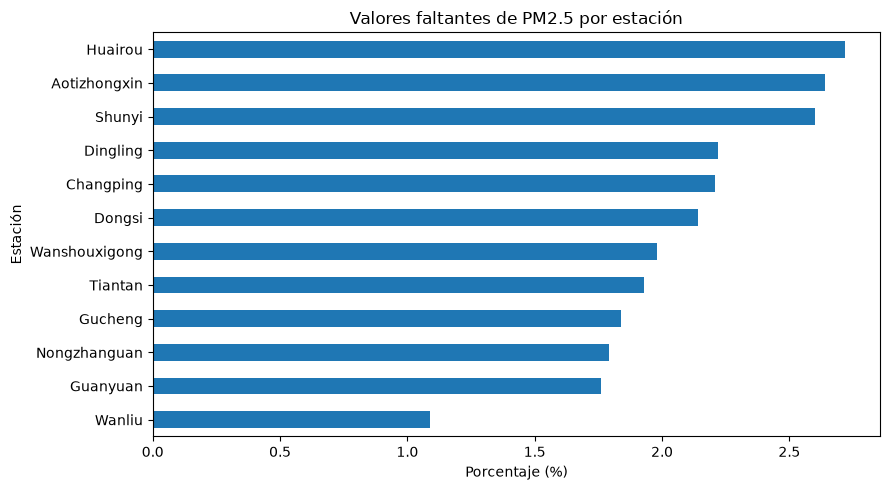

In [22]:
import matplotlib.pyplot as plt

faltantes_estacion = df.groupby("station")["PM2.5"].agg(
    registros="size",
    disponibles="count"
)

faltantes_estacion["faltantes"] = (
    faltantes_estacion["registros"] - faltantes_estacion["disponibles"]
)

faltantes_estacion["porcentaje"] = (
    faltantes_estacion["faltantes"] /
    faltantes_estacion["registros"] * 100
).round(2)

display(faltantes_estacion.sort_values("faltantes", ascending=False))

faltantes_estacion["porcentaje"].sort_values().plot(
    kind="barh",
    figsize=(9, 5)
)

plt.title("Valores faltantes de PM2.5 por estación")
plt.xlabel("Porcentaje (%)")
plt.ylabel("Estación")
plt.tight_layout()
plt.show()

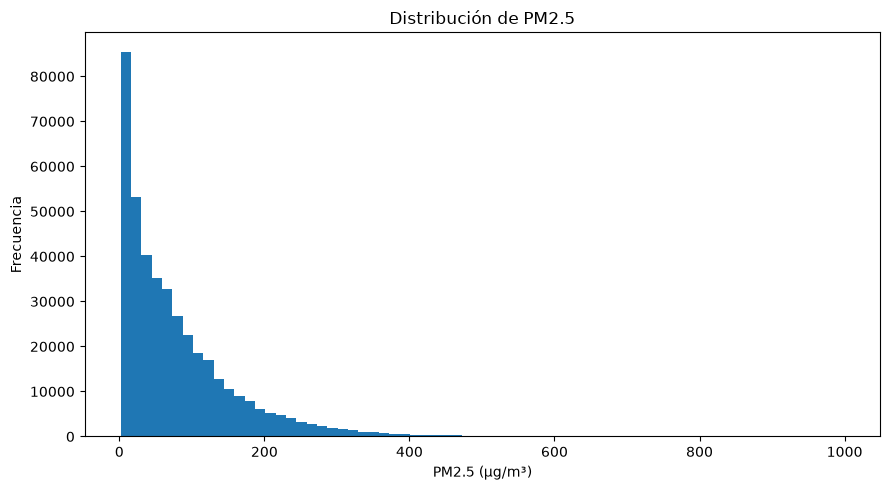

In [23]:
plt.figure(figsize=(9, 5))

plt.hist(df["PM2.5"].dropna(), bins=70)

plt.title("Distribución de PM2.5")
plt.xlabel("PM2.5 (µg/m³)")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.show()

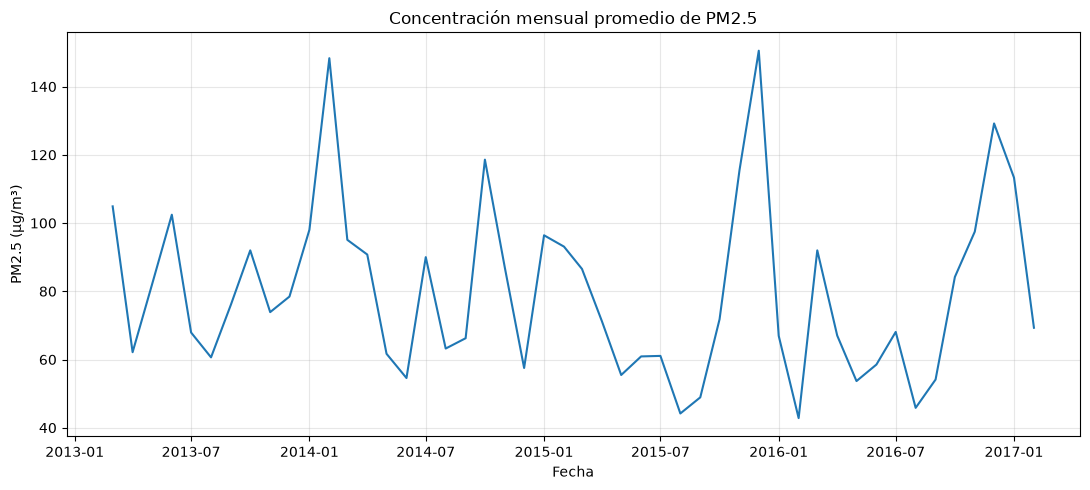

In [24]:
pm25_mensual = (
    df.set_index("fecha_hora")["PM2.5"]
    .resample("MS")
    .mean()
)

plt.figure(figsize=(11, 5))

plt.plot(pm25_mensual.index, pm25_mensual.values)

plt.title("Concentración mensual promedio de PM2.5")
plt.xlabel("Fecha")
plt.ylabel("PM2.5 (µg/m³)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
serie = df.sort_values(
    ["station", "fecha_hora"]
)[["station", "fecha_hora", "PM2.5"]].copy()

grupo = serie.groupby("station")

pm25_siguiente = grupo["PM2.5"].shift(-1)
hora_siguiente = grupo["fecha_hora"].shift(-1)

pares_validos = (
    serie["PM2.5"].notna()
    & pm25_siguiente.notna()
    & hora_siguiente.eq(
        serie["fecha_hora"] + pd.Timedelta(hours=1)
    )
)

print("Pares consecutivos con PM2.5 disponible:", pares_validos.sum())
print("Porcentaje:", round(pares_validos.mean() * 100, 2))

display(
    serie.assign(par_valido=pares_validos)
    .groupby("station")["par_valido"]
    .agg(["sum", "count"])
)